In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
import time, warnings
warnings.filterwarnings("ignore")
from mpl_toolkits.mplot3d import Axes3D

G = 6.67e-11   # m³ / (kg · s²)

# ══════════════════════════════════════════════════════════════════════════════
# 2.1  PRISM FORWARD MODELLING  
# ══════════════════════════════════════════════════════════════════════════════
_SIGNS = np.array([(-1)**(i+j+k) for i in range(2)
                                   for j in range(2)
                                   for k in range(2)], dtype=float)

def _slog(v):       return np.log(np.where(np.abs(v) > 1e-30, np.abs(v), 1e-30))
def _satan(y, x):   return np.arctan2(y, np.where(np.abs(x) > 1e-30, x, 1e-30))
def _r(dx, dy, dz): return np.sqrt(dx**2 + dy**2 + dz**2)

def _kernel_gz(dx, dy, dz):
    return dx*_slog(dy+_r(dx,dy,dz)) + dy*_slog(dx+_r(dx,dy,dz)) - dz*_satan(dx*dy, dz*_r(dx,dy,dz))

def _block(fn, obs_x, obs_y, obs_z, px1, px2, py1, py2, pz1, pz2, scale):
    
    N, M = len(obs_x), len(px1)
    out = np.zeros((N, M))
    cx = [px1, px2]; cy = [py1, py2]; cz = [pz1, pz2]
    s = 0
    for i in range(2):
        for j in range(2):
            for k in range(2):
                dx = cx[i] - obs_x[:, None]
                dy = cy[j] - obs_y[:, None]
                dz = cz[k] - obs_z[:, None]
                out += _SIGNS[s] * fn(dx, dy, dz)
                s += 1
    return G * out * scale

def build_A_gz(obs_x, obs_y, obs_z, px1, px2, py1, py2, pz1, pz2):
    
    B = _block(_kernel_gz, obs_x, obs_y, obs_z, px1, px2, py1, py2, pz1, pz2, 1e5)  # mGal
    print(f"    gz[mGal]   max={np.abs(B).max():.4e}")
    return B

# ══════════════════════════════════════════════════════════════════════════════
# 2.2  DEPTH-WEIGHTING  
# ══════════════════════════════════════════════════════════════════════════════

def build_Wm(pz_c, dx, dy, dz, z0=1.0, beta=2, alpha_s=1.0):
    
    w = 1.0 / (z0 + pz_c) ** (beta / 2.0)
    d = alpha_s * np.sqrt(dx * dy * dz) * w
    return np.maximum(d, 1e-12)

# ══════════════════════════════════════════════════════════════════════════════
# 2.4  ADAPTIVE CGLS REGULARIZATION  
# ══════════════════════════════════════════════════════════════════════════════
def acglsr(A, d_obs, wd, wm, m0=None, Nmax=50, target_phi = 1024,
           delta=0.75, m_low=-np.inf, m_high=np.inf, verbose=True):

    N, M = A.shape
    if m0 is None:
        m0 = np.zeros(M)

    wm_inv = 1.0 / wm

    Aw = (wd[:, None] * A) * wm_inv[None, :]
    dw = wd * (d_obs - A @ m0)

    def Qv(v, mu2):
        return Aw.T @ (Aw @ v) + mu2 * v

    q = Aw.T @ dw

    eps_trial   = 1e3
    phi_d_init  = float(np.dot(dw, dw))
    phi_m_trial = eps_trial**2 * float(np.dot(wm, wm))
    mu2         = phi_d_init / (phi_m_trial + 1e-30)

    if verbose:
        print(f"  Initial μ² = {mu2:.4e} ")

    m_k = np.zeros(M)
    mwk = wm * (m_k - m0)

    fk  = Qv(mwk, mu2) - q
    dk  = fk.copy()

    Qdk  = Qv(dk, mu2)
    denom_init = np.dot(dk, Qdk)
    tk = np.dot(dk, fk) / (denom_init + 1e-30)

    resid  = wd * (A @ m_k - d_obs)
    phi_d  = float(np.dot(resid, resid))
    phi_hist = [phi_d]

    m_best = m_k.copy()

    if verbose:
        print(f"\n  {'Iter':>5}  {'phi_d':>14}  {'mu2':>12}  {'||m||_inf':>10}")
        print("  " + "─" * 52)
        print(f"  {'0':>5}  {phi_d:>14.6e}  {mu2:>12.4e}  {np.abs(m_k).max():>10.4f}")

    for k in range(Nmax):

        mwk = mwk - tk * dk
        m_k = wm_inv * mwk + m0
        m_k = np.clip(m_k, m_low, m_high)
        m_best = m_k.copy()

        resid = wd * (A @ m_k - d_obs)
        phi_d = float(np.dot(resid, resid))
        phi_hist.append(phi_d)

        if verbose:
            print(f"  {k+1:>5}  {phi_d:>14.6e}  {mu2:>12.4e}  {np.abs(m_k).max():>10.4f}")

        if phi_d < target_phi:
            if verbose:
                print(f"\n  ✓ Converged at iteration {k+1}")
            break

        mwk = wm * (m_k - m0)
        mu2 = delta**2 * mu2

        fk_new = Qv(mwk, mu2) - q
        beta_k = np.dot(fk_new, fk_new) / (np.dot(fk, fk) + 1e-30)
        dk_new = fk_new + beta_k * dk

        Qdk  = Qv(dk_new, mu2)
        denom = np.dot(dk_new, Qdk)
        tk = np.dot(dk_new, fk_new) / (denom + 1e-30)

        fk = fk_new
        dk = dk_new

    return m_best, phi_hist

# =====================================================================
# RUN INVERSION ONLY
# =====================================================================

t0 = time.time()
print("=" * 65)
print("  ACGLSR — Single-Prism Test, gz-ONLY ")
print("=" * 65)

# ── Observation grid 32×32 @ 50-m spacing ─────────────────────────────
sp  = 50.0   # in m
x1d = np.arange(sp/2, 1600, sp)
y1d = np.arange(sp/2, 1600, sp)
Xo, Yo  = np.meshgrid(x1d, y1d)
obs_x   = Xo.ravel()
obs_y   = Yo.ravel()
obs_z   = np.zeros(len(obs_x))
N_obs   = len(obs_x)
print(f"  Observations : {N_obs}")

# ── Prism grid 32×32×16 ──────────────────────────────────────────────
nx, ny, nz = 32, 32, 16
dx, dy, dz = 50, 50, 50
xe = np.linspace(0, 1600, nx + 1)
ye = np.linspace(0, 1600, ny + 1)
ze = np.linspace(0, 800,  nz + 1)
iz_g, iy_g, ix_g = np.meshgrid(np.arange(nz), np.arange(ny),
                                np.arange(nx), indexing='ij')
ix_g = ix_g.ravel(); iy_g = iy_g.ravel(); iz_g = iz_g.ravel()
px1 = xe[ix_g]; px2 = xe[ix_g + 1]
py1 = ye[iy_g]; py2 = ye[iy_g + 1]
pz1 = ze[iz_g]; pz2 = ze[iz_g + 1]
pz_c = 0.5 * (pz1 + pz2)
M = len(px1)
print(f"  Prisms       : {nx}×{ny}×{nz}={M}")

# ── True model: x=550m-950m, y=600m-900m, z=200-600 m ──────────────────────────
m_true = np.zeros(M)
cx = 0.5 * (px1 + px2)
cy = 0.5 * (py1 + py2)
cz = 0.5 * (pz1 + pz2)
mask = (cx >= 550) & (cx <= 950) & (cy >= 600) & (cy <= 900) & (cz >= 200) & (cz <= 600)
m_true[mask] = 1000.0  # Density contrast in kg/m3
print(f"  True cells   : {mask.sum()}")

# ── Forward model (gz only) ────────────────────────────────────────────
print("\n  Building design matrix A (gz only) …")
A = build_A_gz(obs_x, obs_y, obs_z, px1, px2, py1, py2, pz1, pz2)
print(f"  A : {A.shape[0]}×{A.shape[1]}")

d_clean = A @ m_true
print(f"  ||d_clean|| = {np.linalg.norm(d_clean):.4e}")


# ── Add 10% zero-mean Gaussian noise ────────────────────────────────
noise_level = 0.1
rng = np.random.default_rng(123)

std_gz = np.std(d_clean) # standard deviation of clean data
sigma_gz = noise_level * std_gz # standard deviation of noise

noise = rng.normal(0.0, sigma_gz, size=N_obs)
d_obs = d_clean + noise

print(f"Clean Gz SD       = {std_gz:.6e} mGal")
print(f"Noise sigma        = {sigma_gz:.6e} mGal")
print(f"Realized noise SD  = {np.std(noise):.6e} mGal")
print(f"Realized ratio     = {np.std(noise)/std_gz:.4f}")

# ── Depth weighting, β=2 for gz 
wm = build_Wm(pz_c, dx, dy, dz, z0=dz/2, beta=3.7, alpha_s=0.1)
#wd = np.ones(len(d_obs))   # replace with 1/sigma_gz per-datum weights if desired
wd = np.full(N_obs, 1.0 / sigma_gz)

# =============================================================================
# CONDITION NUMBER OF THE RAW GRAVITY KERNEL
# =============================================================================
print("\n  Calculating condition number of A ...")

# Singular values of A
singular_values = np.linalg.svd(
    A,
    compute_uv=False
)
sigma_max = singular_values[0]
sigma_min = singular_values[-1]

condition_number_A = sigma_max / sigma_min

print("\n" + "=" * 65)
print("  CONDITION NUMBER — RAW gz KERNEL")
print("=" * 65)

print(f"  Kernel shape             : {A.shape}")
print(f"  Number of observations   : {A.shape[0]}")
print(f"  Number of model cells    : {A.shape[1]}")
print(f"  Largest singular value   : {sigma_max:.6e}")
print(f"  Smallest singular value  : {sigma_min:.6e}")
print(f"  Condition number κ(A)    : {condition_number_A:.6e}")

if condition_number_A < 1e2:
    print("  Interpretation            : Well conditioned")
elif condition_number_A < 1e4:
    print("  Interpretation            : Moderately ill-conditioned")
elif condition_number_A < 1e6:
    print("  Interpretation            : Strongly ill-conditioned")
elif condition_number_A < 1e10:
    print("  Interpretation            : Severely ill-conditioned")
else:
    print("  Interpretation            : Extremely ill-conditioned")

print("=" * 65)

# =============================================================================
# CONDITION NUMBER OF THE WEIGHTED KERNEL USED BY ACGLSR
# =============================================================================
print("\n  Calculating condition number of weighted kernel ...")
wm_inv = 1.0 / wm
Aw = (
    wd[:, None] * A
) * wm_inv[None, :]

# Singular values
singular_values_w = np.linalg.svd(
    Aw,
    compute_uv=False
)
sigma_max_w = singular_values_w[0]
sigma_min_w = singular_values_w[-1]

condition_number_Aw = (
    sigma_max_w / sigma_min_w
)

print("\n" + "=" * 65)
print("  CONDITION NUMBER — WEIGHTED gz KERNEL")
print("=" * 65)

print(f"  Weighted kernel shape    : {Aw.shape}")
print(f"  Largest singular value   : {sigma_max_w:.6e}")
print(f"  Smallest singular value  : {sigma_min_w:.6e}")
print(f"  Condition number κ(Aw)   : {condition_number_Aw:.6e}")

print("=" * 65)

# ── ACGLSR ────────────────────────────────────────────────────────────
print("\n  Running ACGLSR (gz-only")
m_pred, phi_hist = acglsr(
    A, d_obs, wd, wm,
    m0=np.zeros(M),
    Nmax=1200, target_phi = N_obs, delta=0.75,
    m_low= 0, m_high=2000,
    verbose=True
)

d_pred  = A @ m_pred
elapsed = time.time() - t0
rms_fit = np.sqrt(np.mean((d_pred - d_obs)**2))
print(f"\n  RMS error      : {rms_fit:.8f} mGal")
print(f"  Max predicted density : {m_pred.max():.4f} kg/m3")
print(f"  Min predicted density : {m_pred.min():.4f} kg/m3")
print(f"  Elapsed time   : {elapsed:.1f} s")

sh  = (nz, ny, nx)
mt3 = m_true.reshape(sh)
mp3 = m_pred.reshape(sh)

ng = int(np.sqrt(N_obs))
X  = obs_x.reshape(ng, ng)
Y  = obs_y.reshape(ng, ng)

  ACGLSR — Single-Prism Test, gz-ONLY  (Chen et al. 2024, Sec. 3.1.1)
  Observations : 1024
  Prisms       : 32×32×16=16384
  True cells   : 384

  Building design matrix A (gz only) …
    gz[mGal]   max=8.6607e-04
  A : 1024×16384
  ||d_clean|| = 1.9979e+01
Clean Gz SD       = 4.174703e-01 mGal
Noise sigma        = 4.174703e-02 mGal
Realized noise SD  = 4.210729e-02 mGal
Realized ratio     = 0.1009

  Calculating condition number of A ...

  CONDITION NUMBER — RAW gz KERNEL
  Kernel shape             : (1024, 16384)
  Number of observations   : 1024
  Number of model cells    : 16384
  Largest singular value   : 4.687625e-03
  Smallest singular value  : 6.000841e-04
  Condition number κ(A)    : 7.811612e+00
  Interpretation            : Well conditioned

  Calculating condition number of weighted kernel ...

  CONDITION NUMBER — WEIGHTED gz KERNEL
  Weighted kernel shape    : (1024, 16384)
  Largest singular value   : 2.231125e+02
  Smallest singular value  : 5.659883e-01
  Condition 

d_obs =
 [0.05392539 0.08859985 0.16708456 ... 0.07066618 0.04756714 0.126628  ]

 d_pred =
 [0.09576927 0.10590936 0.11744359 ... 0.08336866 0.07796976 0.07294121]

 d_obs maximum = 2.0039066445388363
d_pred maximum = 1.94866943320912

 d_obs minimum = -0.014757170648522583
d_pred minimum = 0.0729412144377233

 d_obs mean = 0.465450565463129
d_pred mean = 0.46570814024271534

Zres =
 [[-0.04184388 -0.01730951  0.04964097 ... -0.00277771 -0.01738034
  -0.05291492]
 [ 0.05041497 -0.092805   -0.01959289 ... -0.02725373 -0.01640973
  -0.02149286]
 [-0.0601693   0.05496019  0.0144502  ... -0.01082998  0.05051208
  -0.0540137 ]
 ...
 [-0.04915552 -0.02983223 -0.05262611 ...  0.01724985 -0.05046058
   0.0585018 ]
 [-0.06823353  0.02377984  0.06884118 ... -0.03172902  0.0437577
   0.045164  ]
 [-0.02288832  0.00575293 -0.00896052 ... -0.01270249 -0.03040263
   0.05368678]]

Zres maximum = 0.12298353589916888
Zres minimum = -0.13892989025778135
Zres mean = -0.0002575747795862906
RMS between ob

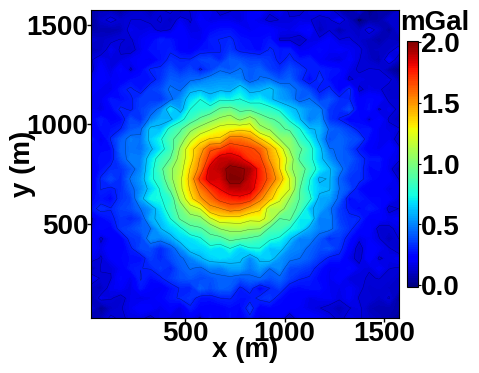

Saved: Fig01_Observed_Gz.png


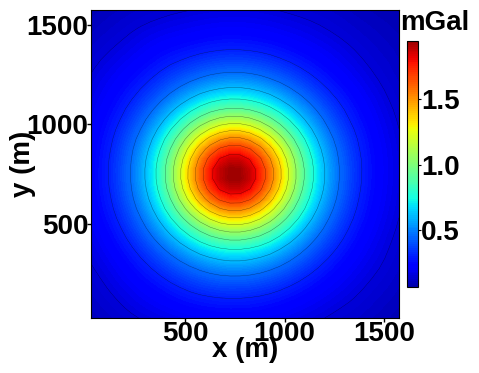

Saved: Fig02_Predicted_Gz.png


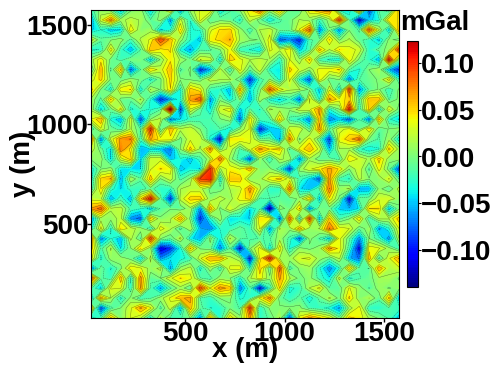

Saved: Fig03_Residual_Gz.png


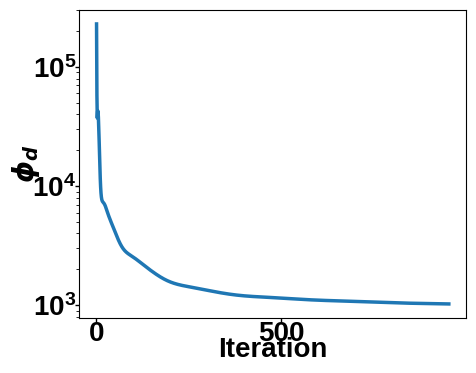

Saved: Fig04_Convergence.png
Convergence data saved: /home/rahul/MTP/INVERSION/ACGLSR_Method/Single_Prism_Model/Single_Prism_Combined_Convergence_all_components/S_P_gz_Conver_Data.xlsx


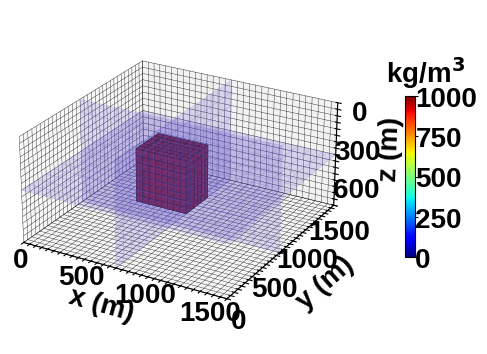

Saved: Fig05_True_3D_Density_Model.png


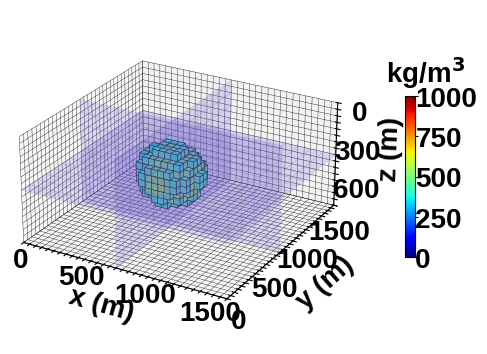

Saved: Fig06_Predicted_3D_Density_Model.png


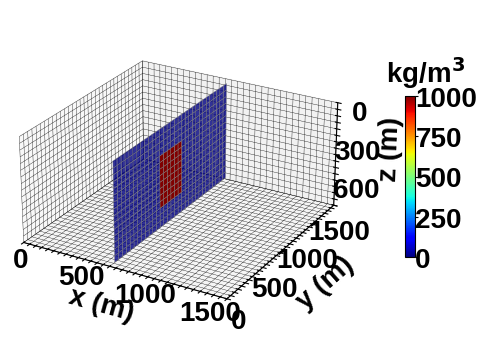

Saved: Fig07_True_YZ_x750.png


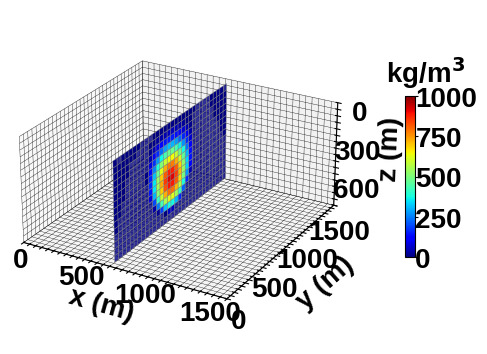

Saved: Fig08_Predicted_YZ_x750.png


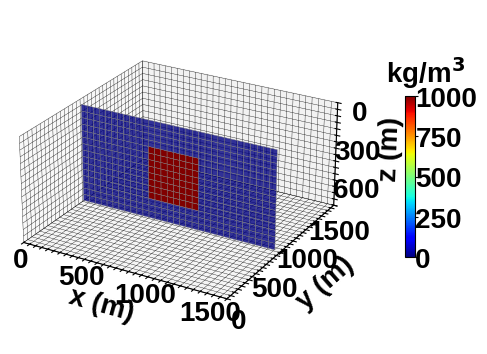

Saved: Fig09_True_XZ_y750.png


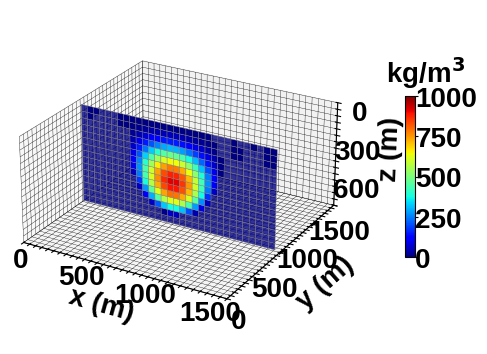

Saved: Fig10_Predicted_XZ_y750.png


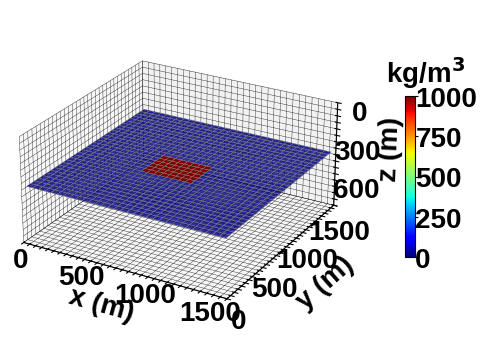

Saved: Fig11_True_XY_z400.png


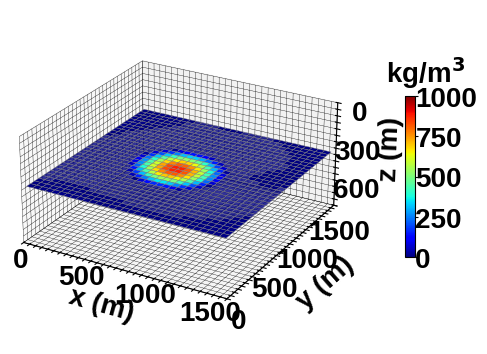

Saved: Fig12_Predicted_XY_z400.png

ALL 12 CNN PUBLICATION FIGURES SAVED SUCCESSFULLY
3-D gridlines : 50 m
X/Y labels    : 200 m
Z labels      : 100 m
Density range : 0–1000 kg/m³
PNG resolution: 600 DPI
No figure titles


In [9]:
# =====================================================================
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import ScalarFormatter, MaxNLocator
from PIL import Image, ImageChops
# =====================================================================
# 1. GLOBAL PUBLICATION SETTINGS
# =====================================================================
BG=AX="white"; TC="black"; DPI=600
mpl.rcParams.update({
    "font.family":"Liberation Sans","font.size":20,
    "axes.labelsize":20,"axes.titlesize":20,"xtick.labelsize":20,"ytick.labelsize":20,
    "legend.fontsize":20,"figure.facecolor":"white",
    "axes.facecolor":"white","savefig.dpi":600,
    "savefig.facecolor":"white","axes.edgecolor":"black",
    "axes.linewidth":.8,"xtick.color":"black","ytick.color":"black",
    "text.color":"black","axes.labelcolor":"black",
    "ps.fonttype":42,"font.weight":"bold","axes.labelweight":"bold",
    "axes.titleweight":"bold"
})
# =====================================================================
# 2. 2-D AXIS STYLE
# =====================================================================
def _style(ax,xl="",yl=""):
    ax.set_facecolor(AX)
    ax.tick_params(axis="both",colors=TC,direction="out",width=1.0,length=3.0,pad=-1.0)
    ax.set_xlabel(xl,color=TC,labelpad=-7.0); ax.set_ylabel(yl,color=TC,labelpad=-7.0)
    for s in ax.spines.values(): s.set_edgecolor(TC); s.set_linewidth(.8)
# =====================================================================
# 3. 2-D COLORBAR
# =====================================================================
def _publication_colorbar(cf,ax,fig,title):
    cb=fig.colorbar(cf,ax=ax,shrink=0.80,pad=0.02,aspect=21)
    cb.ax.set_title(title,color=TC,y=1.01,x=2.4)
    cb.locator=MaxNLocator(nbins=7,steps=[1,2,2.5,5,10]) # Clean tick spacing
    cb.update_ticks()
    cb.ax.tick_params(colors=TC,direction="out",width=.8,length=2,pad=0.0)
    cb.outline.set_edgecolor(TC); cb.outline.set_linewidth(.8)
    return cb

def save_fig(fig,filename,tight=True):
    kw={"dpi":600,"facecolor":BG,"pad_inches":0}
    if tight:kw["bbox_inches"]="tight"
    fig.savefig(filename,**kw)
    plt.show()
    plt.close(fig)
    crop_white_margin(filename,padding=0)
    print("Saved:",filename)

def crop_white_margin(filename,padding=0):
    img=Image.open(filename).convert("RGB")
    bbox=ImageChops.difference(img,Image.new("RGB",img.size,"white")).getbbox()
    if bbox:
        x0,y0,x1,y1=bbox
        img.crop((max(0,x0-padding),max(0,y0-padding),
                  min(img.width,x1+padding),min(img.height,y1+padding))
                ).save(filename,dpi=(DPI,DPI))
                       
# =====================================================================
# 4. OBSERVATION GRID AND DATA RANGE
# =====================================================================
ng=int(np.sqrt(N_obs))
X=obs_x.reshape(ng,ng); Y=obs_y.reshape(ng,ng)
Zobs=d_obs.reshape(ng,ng); Zpred=d_pred.reshape(ng,ng); Zres=Zobs-Zpred
vmin=min(Zobs.min(),Zpred.min()); vmax=max(Zobs.max(),Zpred.max())
rmax=np.max(np.abs(Zres))

# =====================================================================
# 5. GENERAL 2-D Gz PLOT
# =====================================================================
def plot_gz(data,filename,vmin,vmax):
    fig,ax=plt.subplots(figsize=(5,4)); fig.patch.set_facecolor(BG)
    cf=ax.contourf(X,Y,data,levels=150,cmap="jet",vmin=vmin,vmax=vmax)
    ax.contour(X,Y,data,levels=17,colors="k",linewidths=.3,alpha=.5)
    _style(ax,"x (m)","y (m)"); ax.set_aspect("equal")
    _publication_colorbar(cf,ax,fig,"mGal")
    save_fig(fig,filename)
# ============================================================
# Gravity and residual statistics
# ============================================================

# Observed and predicted gravity
print("d_obs =\n", d_obs)
print("\n d_pred =\n", d_pred)

# Maximum values
print("\n d_obs maximum =", np.max(d_obs))
print("d_pred maximum =", np.max(d_pred))

# Minimum values
print("\n d_obs minimum =", np.min(d_obs))
print("d_pred minimum =", np.min(d_pred))

# Mean values
print("\n d_obs mean =", np.mean(d_obs))
print("d_pred mean =", np.mean(d_pred))

# Residual gravity: observed - predicted
print("\nZres =\n", Zres)

# Residual statistics
print("\nZres maximum =", np.max(Zres))
print("Zres minimum =", np.min(Zres))
print("Zres mean =", np.mean(Zres))

# RMS residual
rms = np.sqrt(np.mean(Zres**2))
print("RMS between observed and predicted =", rms)

# =====================================================================
# FIGURES 1–3 — OBSERVED, PREDICTED AND RESIDUAL Gz
# =====================================================================
plot_gz(Zobs,"Fig01_Observed_Gz.png",vmin,vmax)
plot_gz(Zpred,"Fig02_Predicted_Gz.png",vmin,vmax)
plot_gz(Zres,"Fig03_Residual_Gz.png",-rmax,rmax)
# =====================================================================
# FIGURE 4 — CONVERGENCE
# =====================================================================
def plot_convergence(phi,filename):
    fig,ax=plt.subplots(figsize=(5,4))
    ax.semilogy(np.arange(1,len(phi)+1),phi,lw=2.5)
    _style(ax,"Iteration",r"$\phi_d$"); save_fig(fig,filename)

def save_convergence_excel(phi,filename):
    pd.DataFrame({"Iteration":np.arange(1,len(phi)+1),"phi_d":phi}).to_excel(filename,index=False)
    print("Convergence data saved:",filename)

plot_convergence(phi_hist,"Fig04_Convergence.png")

convergence_file="/home/rahul/MTP/INVERSION/ACGLSR_Method/Single_Prism_Model/Single_Prism_Combined_Convergence_all_components/S_P_gz_Conver_Data.xlsx"
save_convergence_excel(phi_hist,convergence_file)

# =====================================================================
# 6. TRUE PRISM BOUNDS
# =====================================================================
px_lo,px_hi=550 ,950 ; py_lo,py_hi=600 ,900; pz_lo,pz_hi=200, 600

# =====================================================================
# 7. COMMON 3-D SETTINGS
# =====================================================================
cmap_3d=plt.cm.jet; norm=plt.Normalize(0,1000)
X3,Y3,Z3=np.meshgrid(xe,ye,ze,indexing="ij")

# =====================================================================
# 8. 3-D AXIS SETTINGS
# 50 m GRIDLINES | X/Y LABELS EVERY 200 m | Z LABELS EVERY 100 m
# =====================================================================
def setup_3d(ax):
    ax.set_xlim(0,1600); ax.set_ylim(0,1600); ax.set_zlim(800,0)

    xg=np.arange(0,1601,50); yg=np.arange(0,1601,50); zg=np.arange(0,801,50)
    ax.set_xticks(xg); ax.set_yticks(yg); ax.set_zticks(zg)
    ax.set_xticklabels([str(v) if v%500==0 else "" for v in xg])
    ax.set_yticklabels([str(v) if v%500==0 else "" for v in yg])
    ax.set_zticklabels([str(v) if v%300==0 else "" for v in zg])

    ax.set_xlabel("x (m)",color=TC,labelpad=0.0)
    ax.set_ylabel("y (m)",color=TC,labelpad=5.0)
    ax.set_zlabel("z (m)",color=TC,labelpad=2.0)
    ax.tick_params(axis="x",colors=TC,direction="out",
                   width=.7,length=3,pad=-5.0)
    ax.tick_params(axis="y",colors=TC,direction="out",
                   width=.7,length=3,pad=-1.0)
    ax.tick_params(axis="z",colors=TC,direction="out",
                   width=.7,length=3,pad=1.0)   
    ax.grid(True)
    for a in [ax.xaxis,ax.yaxis,ax.zaxis]:
        a._axinfo["grid"]["color"]="black"
        a._axinfo["grid"]["linewidth"]=.25
        a._axinfo["grid"]["linestyle"]="-"

    ax.set_facecolor(AX); ax.set_box_aspect((1600,1600,800))
    ax.view_init(elev=25,azim=-60)

# =====================================================================
# 9. TRANSPARENT REFERENCE PLANES
# =====================================================================
def add_density_boundaries(ax,xe,ye,ze,alpha=.2):

    Y,Z=np.meshgrid(ye,ze); X=np.full_like(Y,750.,dtype=float)
    ax.plot_surface(X,Y,Z,color="slateblue",alpha=alpha,
                    edgecolor="slateblue",linewidth=.35,rstride=2,cstride=2,shade=False)

    X,Z=np.meshgrid(xe,ze); Y=np.full_like(X,750.,dtype=float)
    ax.plot_surface(X,Y,Z,color="slateblue",alpha=alpha,
                    edgecolor="slateblue",linewidth=.35,rstride=2,cstride=2,shade=False)

    X,Y=np.meshgrid(xe,ye); Z=np.full_like(X,400.,dtype=float)
    ax.plot_surface(X,Y,Z,color="slateblue",alpha=alpha,
                    edgecolor="slateblue",linewidth=.35,rstride=2,cstride=2,shade=False)

# =====================================================================
# 10. 3-D DENSITY COLORBAR
# =====================================================================
def density_3d_colorbar(fig,ax,cmap,norm):
    sm=mpl.cm.ScalarMappable(cmap=cmap,norm=norm); sm.set_array([])
    cb=fig.colorbar(sm,ax=ax,shrink=0.42,pad=0.13,aspect=16)
    cb.ax.set_title(r"kg/m$^3$",color=TC,y=1.03,x=2.0)
    cb.set_ticks(np.arange(0,1001,250))
    cb.ax.tick_params(colors=TC,direction="out",width=.8,length=2,pad=-2.0)
    cb.outline.set_edgecolor(TC); cb.outline.set_linewidth(.8)
    return cb

# =====================================================================
# 11. GENERAL 3-D DENSITY MODEL
# =====================================================================
def plot_3d_model(arr,filename,threshold):

    #fig=plt.figure(figsize=(9,8),constrained_layout=True); fig.patch.set_facecolor(BG)
    fig=plt.figure(figsize=(6,5)); fig.patch.set_facecolor(BG)
    ax=fig.add_subplot(111,projection="3d")

    filled=arr>threshold
    fc=np.zeros((*arr.shape,4)); fc[filled]=cmap_3d(norm(arr[filled]))

    # 50 m voxel boundaries are drawn with edgecolor/linewidth
    ax.voxels(X3,Y3,Z3,filled.transpose(2,1,0),
              facecolors=fc.transpose(2,1,0,3),
              edgecolor="black",linewidth=0.4,alpha=1.0,shade=False)

    add_density_boundaries(ax,xe,ye,ze,alpha=.2)
    setup_3d(ax)
    density_3d_colorbar(fig,ax,cmap_3d,norm)

    save_fig(fig,filename)
    plt.show(); plt.close(fig)

# =====================================================================
# FIGURES 5–6 — TRUE AND PREDICTED 3-D DENSITY MODELS
# =====================================================================
plot_3d_model(mt3,"Fig05_True_3D_Density_Model.png",50.)
plot_3d_model(mp3,"Fig06_Predicted_3D_Density_Model.png",400.)

# =====================================================================
# 12. TRUE PRISM BOUNDARY ON PREDICTED SLICES
# =====================================================================
def add_true_prism_boundary(ax,x_slice=None,y_slice=None,z_slice=None):

    if x_slice is not None:
        ax.plot([x_slice]*5,[py_lo,py_hi,py_hi,py_lo,py_lo],
                [pz_lo,pz_lo,pz_hi,pz_hi,pz_lo],
                color="black",linewidth=1.5,linestyle="--",zorder=10)

    elif y_slice is not None:
        ax.plot([px_lo,px_hi,px_hi,px_lo,px_lo],[y_slice]*5,
                [pz_lo,pz_lo,pz_hi,pz_hi,pz_lo],
                color="black",linewidth=1.5,linestyle="--",zorder=10)

    elif z_slice is not None:
        ax.plot([px_lo,px_hi,px_hi,px_lo,px_lo],
                [py_lo,py_lo,py_hi,py_hi,py_lo],[z_slice]*5,
                color="black",linewidth=2.,linestyle="--",zorder=10)
# =====================================================================
# 13. GENERAL 3-D DENSITY SLICE
# =====================================================================
def plot_density_slice(model3d,x_slice=None,y_slice=None,z_slice=None,
                       filename="",show_boundary=False):

    fig=plt.figure(figsize=(6,5)); fig.patch.set_facecolor(BG)
    ax=fig.add_subplot(111,projection="3d")

    xc=.5*(xe[:-1]+xe[1:]); yc=.5*(ye[:-1]+ye[1:]); zc=.5*(ze[:-1]+ze[1:])

    if x_slice is not None:
        ix=np.argmin(np.abs(xc-x_slice))
        Y,Z=np.meshgrid(yc,zc); X=np.full_like(Y,xc[ix]); rho=model3d[:,:,ix]

    elif y_slice is not None:
        iy=np.argmin(np.abs(yc-y_slice))
        X,Z=np.meshgrid(xc,zc); Y=np.full_like(X,yc[iy]); rho=model3d[:,iy,:]

    elif z_slice is not None:
        iz=np.argmin(np.abs(zc-z_slice))
        X,Y=np.meshgrid(xc,yc); Z=np.full_like(X,zc[iz]); rho=model3d[iz,:,:]

    else:
        plt.close(fig); return

    fc=cmap_3d(norm(rho)); fc[...,3]=np.where(np.abs(rho)>1e-12,1.,0.8)

    ax.plot_surface(X,Y,Z,facecolors=fc,rstride=1,cstride=1,
                    linewidth=.3,edgecolor="gray",shade=False,antialiased=True)

    # if show_boundary:
    #     add_true_prism_boundary(ax,x_slice,y_slice,z_slice)

    setup_3d(ax); density_3d_colorbar(fig,ax,cmap_3d,norm)

    save_fig(fig,filename)
    plt.show(); plt.close(fig)

# =====================================================================
# FIGURES 7–12 — TRUE AND PREDICTED DENSITY SLICES
# =====================================================================
plot_density_slice(mt3,x_slice=750,filename="Fig07_True_YZ_x750.png")
plot_density_slice(mp3,x_slice=750,filename="Fig08_Predicted_YZ_x750.png",show_boundary=True)

plot_density_slice(mt3,y_slice=750,filename="Fig09_True_XZ_y750.png")
plot_density_slice(mp3,y_slice=750,filename="Fig10_Predicted_XZ_y750.png",show_boundary=True)

plot_density_slice(mt3,z_slice=400,filename="Fig11_True_XY_z400.png")
plot_density_slice(mp3,z_slice=400,filename="Fig12_Predicted_XY_z400.png",show_boundary=True)

# =====================================================================
# COMPLETE
# =====================================================================
print("\n==============================================")
print("ALL 12 CNN PUBLICATION FIGURES SAVED SUCCESSFULLY")
print("==============================================")
print("3-D gridlines : 50 m")
print("X/Y labels    : 200 m")
print("Z labels      : 100 m")
print("Density range : 0–1000 kg/m³")
print("PNG resolution: 600 DPI")
print("No figure titles")
print("==============================================")

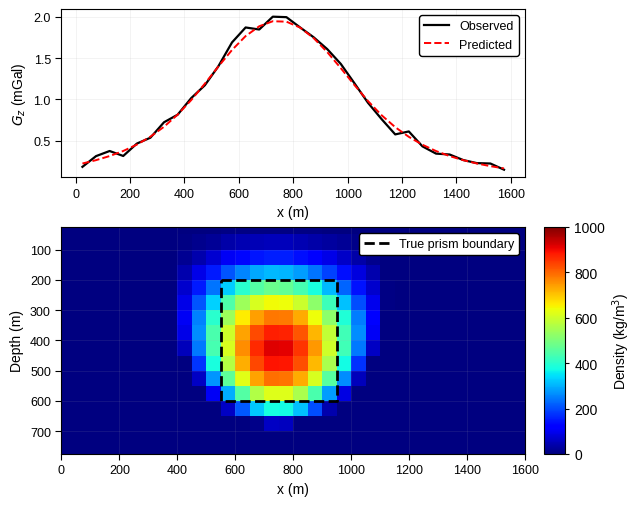

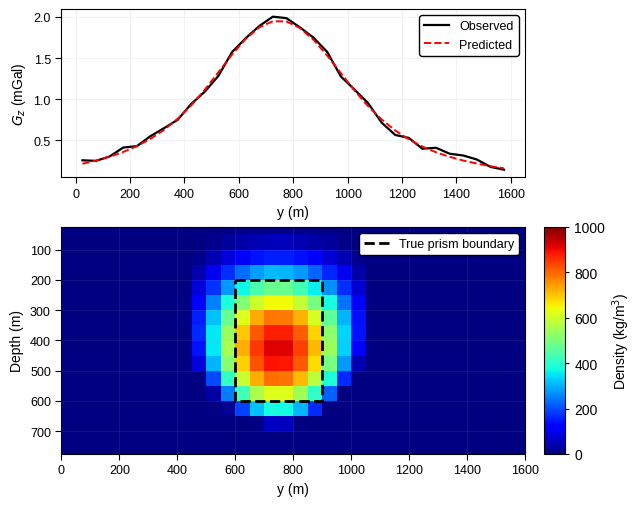

In [5]:
# =====================================================================
# 14–15. EW/NS Gz PROFILE + gz DENSITY SECTION
# =====================================================================
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import matplotlib as mpl


# =====================================================================
# PROFILE + DENSITY-SECTION FUNCTION
# =====================================================================

def plot_profile_density_section(direction="EW", coordinate=750,
                                 filename="Profile_Density_Section.png"):

    # --- True prism bounds ---
    px_lo, px_hi = 550., 950.
    py_lo, py_hi = 600., 900.
    pz_lo, pz_hi = 200., 600.

    # --- Model cell centres ---
    xc, yc, zc = [(a[:-1] + a[1:]) / 2 for a in (xe, ye, ze)]

    # --- Select profile and density section ---
    if direction.upper() == "EW":
        i = np.argmin(abs(Y[:, 0] - coordinate))
        profile, obs, pred = X[i], Zobs[i], Zpred[i]

        pd.DataFrame({
            "x (m)": profile,
            "Observed Gz (mGal)": obs,
            "Predicted Gz (mGal)": pred
        }).to_excel("XZ_Gravity_Profile_y750.xlsx", index=False)

        j = np.argmin(abs(yc - coordinate))
        section = mp3[:, j, :]
        Xsec, Zsec = np.meshgrid(xc, zc)
        xlabel = "x (m)"

    elif direction.upper() == "NS":
        i = np.argmin(abs(X[0] - coordinate))
        profile, obs, pred = Y[:, i], Zobs[:, i], Zpred[:, i]

        pd.DataFrame({
            "y (m)": profile,
            "Observed Gz (mGal)": obs,
            "Predicted Gz (mGal)": pred
        }).to_excel("YZ_Gravity_Profile_x750.xlsx", index=False)

        j = np.argmin(abs(xc - coordinate))
        section = mp3[:, :, j]
        Xsec, Zsec = np.meshgrid(yc, zc)
        xlabel = "y (m)"

    else:
        raise ValueError("direction must be 'EW' or 'NS'")

    # --- Figure layout ---
    fig = plt.figure(figsize=(6, 5))
    gs = fig.add_gridspec(
        2, 2, height_ratios=[1, 1.35],
        width_ratios=[1, .045], hspace=.25, wspace=.08
    )
    ax1 = fig.add_subplot(gs[0, 0])
    ax2 = fig.add_subplot(gs[1, 0])
    cax = fig.add_subplot(gs[1, 1])
    fig.patch.set_facecolor(BG)

    # --- (a) Gz profile ---
    ax1.plot(profile, obs, "k", lw=1.6, label="Observed")
    ax1.plot(profile, pred, "r--", lw=1.4, label="Predicted")
    _style(ax1, xlabel, r"$G_z$ (mGal)")
    ax1.tick_params(axis="both", labelsize=9)
    ax1.grid(True, lw=.4, alpha=.25)
    ax1.legend(
        loc="upper right", frameon=True, framealpha=1,
        edgecolor="black", fontsize=9
    )

    # --- (b) gz density section ---
    pcm = ax2.pcolormesh(
        Xsec, Zsec, section, cmap="jet",
        vmin=0, vmax=1000, shading="auto"
    )
    ax2.set_ylim(zc.max(), zc.min())
    _style(ax2, xlabel, "Depth (m)")
    ax2.tick_params(axis="both", labelsize=9)
    ax2.grid(True, lw=.4, alpha=.20)

    # --- True prism boundary ---
    boundary_x = (
        [px_lo, px_hi, px_hi, px_lo, px_lo]
        if direction.upper() == "EW"
        else [py_lo, py_hi, py_hi, py_lo, py_lo]
    )
    boundary_z = [pz_lo, pz_lo, pz_hi, pz_hi, pz_lo]

    ax2.plot(
        boundary_x, boundary_z,
        "k--", lw=2.0, zorder=10,
        label="True prism boundary"
    )
    ax2.legend(
        loc="upper right", fontsize=9,
        frameon=True, framealpha=1, edgecolor="black"
    )

    # --- Density colorbar ---
    cb = fig.colorbar(pcm, cax=cax)
    cb.set_label(r"Density (kg/m$^3$)", fontsize=10, color=TC)
    cb.ax.tick_params(
        labelsize=10, colors=TC,
        direction="out", width=.8, length=3
    )
    cb.outline.set_edgecolor(TC)
    cb.outline.set_linewidth(.8)

    # --- Save figure ---
    fig.subplots_adjust(
        left=.10, right=.94, top=.97, bottom=.08
    )
    fig.savefig(
        filename, dpi=600,
        bbox_inches="tight", facecolor=BG
    )
    plt.show()
    plt.close(fig)
# =====================================================================
# FIGURE 13 — EW/XZ AT y = 750 m
# =====================================================================
plot_profile_density_section(
    "EW", 750,
    "Fig14_EW_XZ_Profile_Density_Section_y750.png"
)
# =====================================================================
# FIGURE 14 — NS/YZ AT x = 750 m
# =====================================================================
plot_profile_density_section(
    "NS", 750,
    "Fig15_NS_YZ_Profile_Density_Section_x750.png"
)

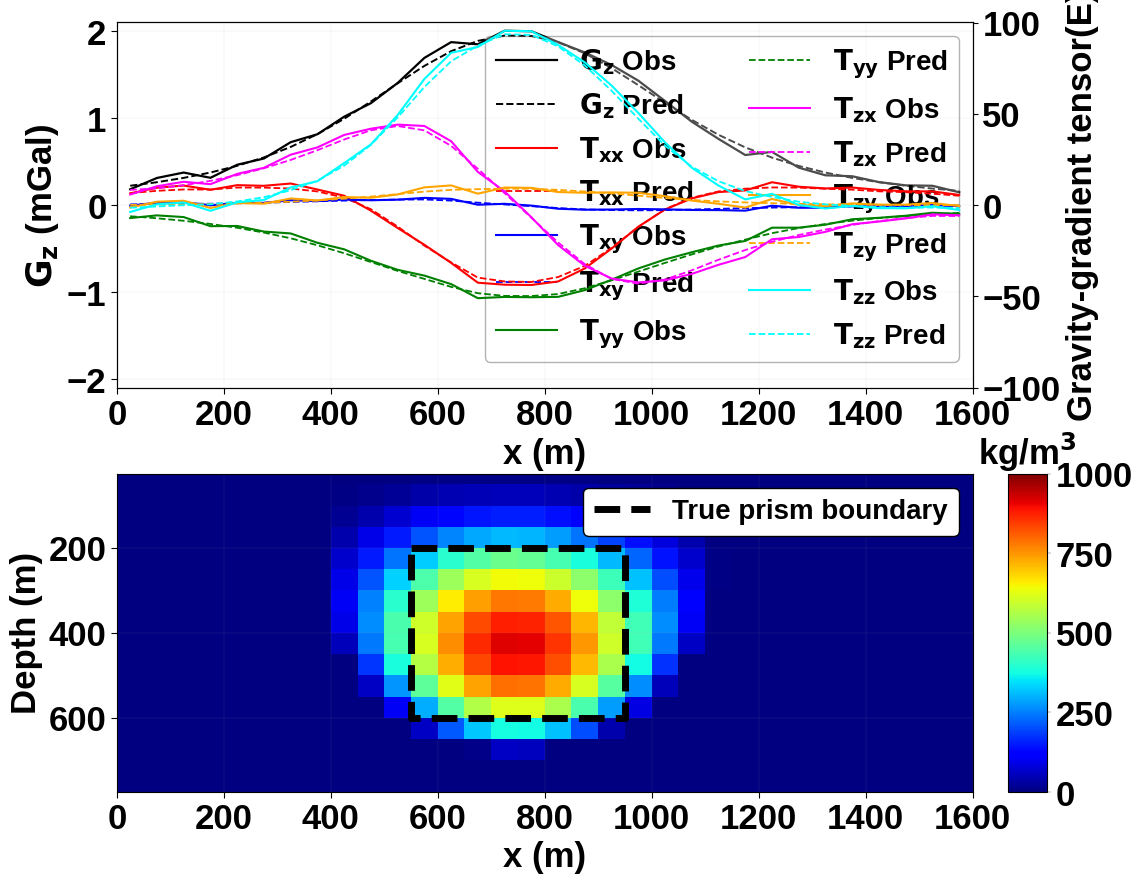

Saved: Fig16_All_XZ_Profiles_Gz_Density_Section_y750.png


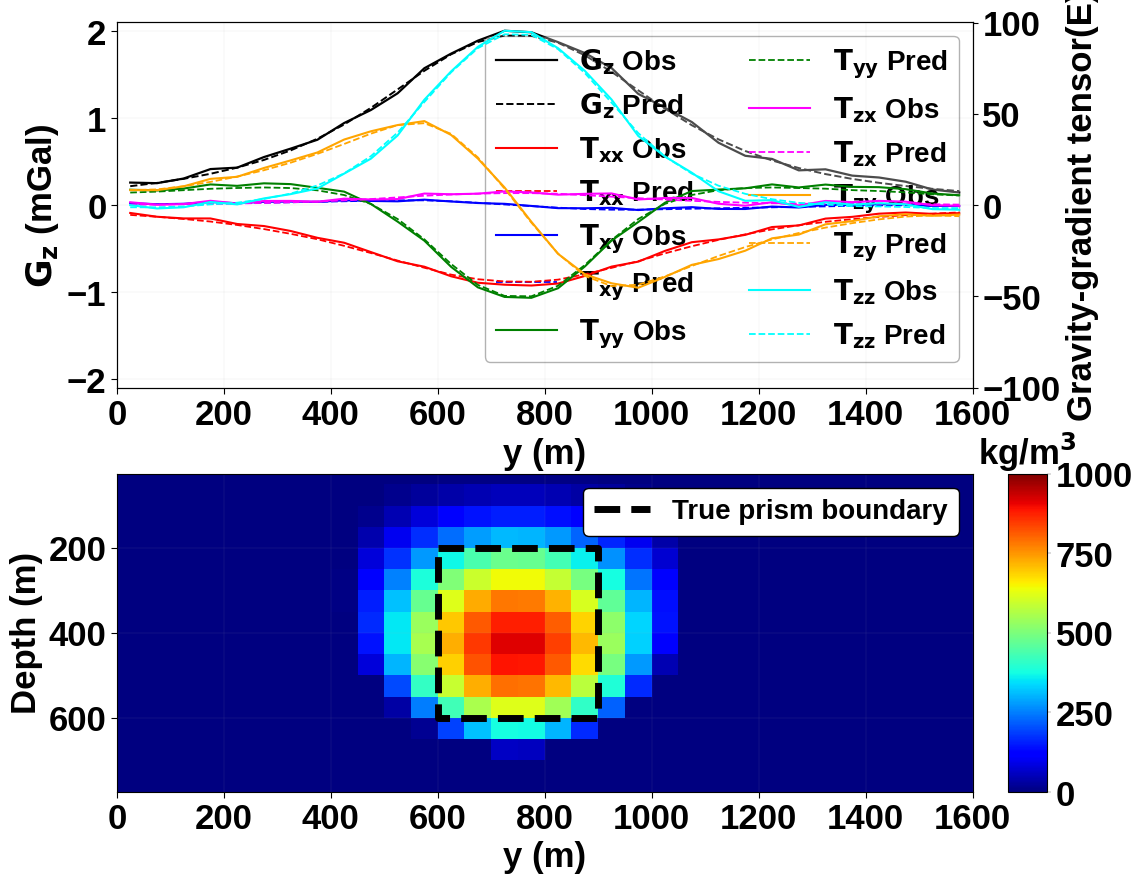

Saved: Fig17_All_YZ_Profiles_Gz_Density_Section_x750.png


In [6]:
# =====================================================================
# 17–18. ALL COMPONENT PROFILES + Gz DENSITY SECTIONS
# LEFT AXIS: Gz (mGal) | RIGHT AXIS: TENSOR COMPONENTS (E)
# =====================================================================
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import matplotlib as mpl
import glob
# ---------------------------------------------------------------------
# 1. PUBLICATION SETTINGS
# ---------------------------------------------------------------------
BG=AX="white"; TC="black"; DPI=600
mpl.rcParams.update({
    "font.family":"Liberation Sans","font.size":25,
    "axes.labelsize":25,"axes.titlesize":25,"xtick.labelsize":25,"ytick.labelsize":25,
    "legend.fontsize":20,"figure.facecolor":"white",
    "axes.facecolor":"white","savefig.dpi":600,
    "savefig.facecolor":"white","axes.edgecolor":"black",
    "axes.linewidth":.8,"xtick.color":"black","ytick.color":"black",
    "text.color":"black","axes.labelcolor":"black",
    "ps.fonttype":42,"font.weight":"bold","axes.labelweight":"bold",
    "axes.titleweight":"bold"
})

def save_fig(fig,filename,tight=True):
    fig.tight_layout()
    kw={"dpi":600,"facecolor":BG,"pad_inches":0}
    if tight:kw["bbox_inches"]="tight"
    fig.savefig(filename,**kw)
    plt.show()
    plt.close(fig)
    crop_white_margin(filename,padding=0)
    print("Saved:",filename)

def crop_white_margin(filename,padding=0):
    img=Image.open(filename).convert("RGB")
    bbox=ImageChops.difference(img,Image.new("RGB",img.size,"white")).getbbox()
    if bbox:
        x0,y0,x1,y1=bbox
        img.crop((max(0,x0-padding),max(0,y0-padding),
                  min(img.width,x1+padding),min(img.height,y1+padding))
                ).save(filename,dpi=(DPI,DPI))
        
# =====================================================================
# TRUE PRISM BOUNDS
# =====================================================================
px_lo, px_hi = 550, 950
py_lo, py_hi = 600, 900
pz_lo, pz_hi = 200, 600
# =====================================================================
# COMPONENTS AND COLOURS
# =====================================================================
components = {
    "Gz":("Gravity",r"\mathbf{G}_{\mathbf{z}}","mGal"),
    "Txx":("txx",r"\mathbf{T}_{\mathbf{xx}}","E"),
    "Txy":("txy",r"\mathbf{T}_{\mathbf{xy}}","E"),
    "Tyy":("tyy",r"\mathbf{T}_{\mathbf{yy}}","E"),
    "Tzx":("tzx",r"\mathbf{T}_{\mathbf{zx}}","E"),
    "Tzy":("tzy",r"\mathbf{T}_{\mathbf{zy}}","E"),
    "Tzz":("tzz",r"\mathbf{T}_{\mathbf{zz}}","E")
}
comp_colors = {
    "Gz":"black", "Txx":"red", "Txy":"blue", "Tyy":"green",
    "Tzx":"magenta", "Tzy":"orange", "Tzz":"cyan"
}

# =====================================================================
# 2-D AXIS STYLE
# =====================================================================
def _style(ax,xl="",yl=""):
    ax.set_facecolor(AX)
    ax.tick_params(axis="both",colors=TC,
                   direction="out",width=.8,length=4)
    ax.set_xlabel(xl,color=TC)
    ax.set_ylabel(yl,color=TC)
    for s in ax.spines.values():
        s.set_edgecolor(TC); s.set_linewidth(.8)
        
# =====================================================================
# READ XZ/YZ PROFILE DATA
# =====================================================================
def read_profiles(direction):
    data = {}
    for comp,(name,label,unit) in components.items():
        file = (f"XZ_{name}_Profile_y750.xlsx" if direction=="XZ"
                else f"YZ_{name}_Profile_x750.xlsx")
        coord = "x (m)" if direction=="XZ" else "y (m)"
        df = pd.read_excel(file)
        data[comp] = {
            "coord":df[coord].to_numpy(),
            "obs":df.iloc[:,1].to_numpy(),
            "pred":df.iloc[:,2].to_numpy(),
            "label":label,"unit":unit
        }
    return data
# =====================================================================
# COMMON Y-AXIS LIMITS
# =====================================================================
def get_common_limits(xz,yz):
    gz = np.concatenate([
        xz["Gz"]["obs"],xz["Gz"]["pred"],
        yz["Gz"]["obs"],yz["Gz"]["pred"]
    ])
    tensor = np.concatenate([
        np.concatenate([d[c]["obs"],d[c]["pred"]])
        for c in ["Txx","Txy","Tyy","Tzx","Tzy","Tzz"] for d in [xz,yz]
    ])
    return ((-1.05*np.max(np.abs(gz)),1.05*np.max(np.abs(gz))),
            (-1.05*np.max(np.abs(tensor)),1.05*np.max(np.abs(tensor))))

# =====================================================================
# PLOT PROFILES + Gz DENSITY SECTION
# =====================================================================
def plot_profiles_density(direction,data,gz_ylim,tensor_ylim,filename):

    # --- Model cell centres and density section ---
    xc,yc,zc = [(a[:-1]+a[1:])/2 for a in (xe,ye,ze)]

    if direction=="XZ":
        j=np.argmin(np.abs(yc-750)); section=mp3[:,j,:]
        Xsec,Zsec=np.meshgrid(xc,zc); xlabel="x (m)"
        bx=[px_lo,px_hi,px_hi,px_lo,px_lo]
    else:
        j=np.argmin(np.abs(xc-750)); section=mp3[:,:,j]
        Xsec,Zsec=np.meshgrid(yc,zc); xlabel="y (m)"
        bx=[py_lo,py_hi,py_hi,py_lo,py_lo]

    bz=[pz_lo,pz_lo,pz_hi,pz_hi,pz_lo]

    # --- Figure layout ---
    fig=plt.figure(figsize=(12,10))
    gs=fig.add_gridspec(
        2,2,height_ratios=[1.15,1],width_ratios=[1,.045],
        hspace=0.25,wspace=.08
    )
    ax1=fig.add_subplot(gs[0,0])
    ax2=fig.add_subplot(gs[1,0])
    cax=fig.add_subplot(gs[1,1])
    fig.patch.set_facecolor(BG)

    # --- Gz profile ---
    v=data["Gz"]
    ax1.plot(v["coord"],v["obs"],"k-",lw=1.6,label=r"$\mathbf{G}_{\mathbf{z}}$ Obs")
    ax1.plot(v["coord"],v["pred"],"k--",lw=1.4,label=r"$\mathbf{G}_{\mathbf{z}}$ Pred")
    ax1.set(xlim=(0,1600),ylim=gz_ylim,xticks=np.arange(0,1601,200))
    _style(ax1,xlabel,r"$\mathbf{G}_{\mathbf{z}}$ (mGal)")
    ax1.grid(True,lw=.35,alpha=.25)

    # --- Tensor components: right Y-axis ---
    ax1r=ax1.twinx()
    for comp in ["Txx","Txy","Tyy","Tzx","Tzy","Tzz"]:
        v,c=data[comp],comp_colors[comp]
        ax1r.plot(v["coord"],v["obs"],color=c,lw=1.5,
                  label=rf"${v['label']}$ Obs")
        ax1r.plot(v["coord"],v["pred"],color=c,lw=1.3,ls="--",
                  label=rf"${v['label']}$ Pred")
    ax1r.set_ylim(*tensor_ylim)
    ax1r.set_ylabel("Gravity-gradient tensor(E)")
    ax1r.spines["right"].set_color(TC)

    # --- Combined legend ---
    h1,l1=ax1.get_legend_handles_labels()
    h2,l2=ax1r.get_legend_handles_labels()
    
    leg=ax1.legend(
        h1+h2,l1+l2,loc="upper right",ncol=2,
        frameon=True,framealpha=0.3,edgecolor="black",
        borderpad=.4,handlelength=2.2
    )
    # --- Density section ---
    pcm=ax2.pcolormesh(
        Xsec,Zsec,section,cmap="jet",vmin=0,vmax=1000,shading="auto"
    )
    ax2.set(xlim=(0,1600),ylim=(zc.max(),zc.min()),
            xticks=np.arange(0,1601,200))
    _style(ax2,xlabel,"Depth (m)")
    ax2.grid(True,lw=.35,alpha=.20)

    # --- True prism boundary ---
    ax2.plot(
        bx,bz,"k--",lw=5,zorder=10,label="True prism boundary"
    )
    ax2.legend(
        loc="upper right",
        frameon=True,framealpha=1.0,edgecolor="black"
    )
    
    # --- Density colourbar ---
    cb=fig.colorbar(pcm,cax=cax)
    cb.ax.set_title(r"kg/m$^3$",color=TC)
    cb.ax.tick_params(colors=TC,
        direction="out",width=.2,length=3
    )
    cb.outline.set_edgecolor(TC); cb.outline.set_linewidth(.8)
    save_fig(fig,filename)
    plt.show()
    plt.close(fig)
# =====================================================================
# READ DATA AND COMMON LIMITS
# =====================================================================
xz_data=read_profiles("XZ")
yz_data=read_profiles("YZ")
gz_ylim,tensor_ylim=get_common_limits(xz_data,yz_data)

# =====================================================================
# FIGURE 16 — XZ
# =====================================================================
plot_profiles_density(
    "XZ",xz_data,gz_ylim,tensor_ylim,
    "Fig16_All_XZ_Profiles_Gz_Density_Section_y750.png"
)
# =====================================================================
# FIGURE 17 — YZ
# =====================================================================
plot_profiles_density(
    "YZ",yz_data,gz_ylim,tensor_ylim,
    "Fig17_All_YZ_Profiles_Gz_Density_Section_x750.png"
)